# Ghost-overlay models: phase estimator + nearest CORRECT neighbour (one model per exercise)
---
**What this script builds for each of Exercies**
1. A *causal* per-frame featuriser (EMA smoothing -> pelvis/torso normalisation -> joint angles + positions + angular velocity).
   Only past frames are used, so training and real time see identical features.
2. A **phase estimator** trained on CORRECT reps only (target = frame_index / rep_length, encoded as sin/cos).
   kNN and ExtraTrees are compared with person-disjoint CV; the better one is kept.
3. A **phase-indexed bank** of every correct frame (features + normalised 26x2 pose for the ghost).
4. **Per-phase-bin distance thresholds** from leave-one-person-out nearest-correct distances (correct reps only).
5. A `LiveCoach` class: `push_frame(26x2 points)` -> phase estimate, distance to nearest correct frame at that phase,
   threshold, ratio, flag, and the top-3 nearest correct neighbours (with a match confidence) for the ghost overlay.
6. Validation: phase error on held-out persons, cue AUROC (flawed vs perfect reps), and a frame-by-frame REPLAY of one
   held-out FLAWED rep from frame 0 (table + CSV + ghost PNG).
7. Final refit on ALL persons and saving `<Ex>_ghost.pkl` + `manifest.json`.

In [1]:
import os, re, sys, json, glob, time, warnings
import numpy as np
import pandas as pd
import joblib
import matplotlib
if not os.environ.get("DISPLAY") and "ipykernel" not in sys.modules:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from collections import defaultdict
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import pairwise_distances, roc_auc_score
from sklearn.model_selection import train_test_split, GroupKFold

warnings.filterwarnings("ignore")

## Config (edit here)

In [ ]:
SEED = 42
np.random.seed(SEED)

DATA_ROOT = "/kaggle/input/datasets/almutalem/rehab24-6-2d-30fps-repetition-extracted/processed_repetitions/2d_joints"
OUT_DIR = "/kaggle/working/ghost_models" if os.path.isdir("/kaggle/working") else "./ghost_models"
os.makedirs(OUT_DIR, exist_ok=True)
EXERCISES = ["Ex1", "Ex2", "Ex3", "Ex4", "Ex5", "Ex6"]

# causal featuriser
EMA_ALPHA = 0.5        # smoothing of raw points (1.0 = no smoothing). Lower = smoother but more lag
VEL_LAG   = 5          # angular velocity = angle[t] - angle[t-VEL_LAG]   (frames at YOUR camera fps)
# phase bank / matching
N_BINS        = 20     # number of phase bins for thresholds
PHASE_WINDOW  = 0.12   # only compare with correct frames whose phase is within +-window (circular) of the estimate
THR_PCT       = 95.0   # threshold = this percentile of leave-one-person-out nearest distances (per phase bin)
THR_MIN_N     = 40     # min samples in a bin, else fall back to the global percentile
PERSIST       = 4      # frames in a row above threshold before flag=True
WARMUP        = 6      # frames before the matcher is considered reliable
N_NEIGHBOURS  = 3
# replay / plots
PRINT_EVERY   = 4
INVERT_Y      = True   # image coordinates (y down). Set False if your y axis points up.
SPLIT_TEST_SIZE = 0.2  # same person-disjoint split as the notebooks (seed 42)



print("DATA_ROOT:", DATA_ROOT)
print("OUT_DIR  :", OUT_DIR)
print("EXERCISES:", EXERCISES)

DATA_ROOT: /kaggle/input/datasets/almutalem/rehab24-6-2d-30fps-repetition-extracted/processed_repetitions/2d_joints
OUT_DIR  : /kaggle/working/ghost_models
EXERCISES: ['Ex1', 'Ex2', 'Ex3', 'Ex4', 'Ex5', 'Ex6']


## Skeleton definition + per-exercise joint groups

In [3]:
JN = {
    "Hips": 0, "Spine": 1, "Spine1": 2, "Neck": 3, "Head": 4, "Head_end": 5,
    "LeftShoulder": 6, "LeftArm": 7, "LeftForeArm": 8, "LeftHand": 9, "LeftHand_end": 10,
    "RightShoulder": 11, "RightArm": 12, "RightForeArm": 13, "RightHand": 14, "RightHand_end": 15,
    "LeftUpLeg": 16, "LeftLeg": 17, "LeftFoot": 18, "LeftToeBase": 19, "LeftToeBase_end": 20,
    "RightUpLeg": 21, "RightLeg": 22, "RightFoot": 23, "RightToeBase": 24, "RightToeBase_end": 25,
}
UPPER_BONES = [(0, 1), (1, 2), (2, 3), (3, 4), (6, 7), (7, 8), (8, 9), (11, 12), (12, 13), (13, 14),
               (0, 6), (0, 11), (1, 6), (1, 11)]
LEG_BONES = [(0, 16), (0, 21), (16, 17), (17, 18), (18, 19), (19, 20), (21, 22), (22, 23), (23, 24), (24, 25)]
HEAD_TIP = [(4, 5), (9, 10), (14, 15)]
FULL_BONES = UPPER_BONES + LEG_BONES + HEAD_TIP

ARM_J = ["Neck", "Head", "LeftArm", "LeftForeArm", "LeftHand", "RightArm", "RightForeArm", "RightHand", "Spine1"]
LEG_J = ["Neck", "Head", "Spine1", "LeftUpLeg", "LeftLeg", "LeftFoot", "LeftToeBase",
         "RightUpLeg", "RightLeg", "RightFoot", "RightToeBase"]
FULL_J = sorted(set(ARM_J + LEG_J))

# exercise -> joints whose normalised (x,y) go into the feature vector
EX_JOINTS = {
    "Ex1": ARM_J,   # arm abduction
    "Ex2": ARM_J,   # arms V/W shape
    "Ex3": FULL_J,  # push-up (whole body, head-to-plank line)
    "Ex4": LEG_J,   # standing side leg raise (left/right handled implicitly: bank contains both sides)
    "Ex5": LEG_J,   # lunge
    "Ex6": LEG_J,   # squat
}

# generic joint angles used for every exercise (a, vertex, c)
ANGLE_DEFS = [
    ("Neck", "LeftShoulder", "LeftArm"), ("Neck", "RightShoulder", "RightArm"),
    ("LeftShoulder", "LeftArm", "LeftForeArm"), ("RightShoulder", "RightArm", "RightForeArm"),
    ("LeftArm", "LeftForeArm", "LeftHand"), ("RightArm", "RightForeArm", "RightHand"),
    ("Hips", "Spine1", "Neck"),
    ("LeftUpLeg", "LeftLeg", "LeftFoot"), ("RightUpLeg", "RightLeg", "RightFoot"),
    ("Spine", "LeftUpLeg", "LeftLeg"), ("Spine", "RightUpLeg", "RightLeg"),
    ("LeftLeg", "LeftFoot", "LeftToeBase"), ("RightLeg", "RightFoot", "RightToeBase"),
]
N_ANG = len(ANGLE_DEFS) + 4   # + shoulder tilt, hip tilt, trunk lean, head-neck-hips line

## Causal per-frame featuriser (identical in training and real time)

In [4]:
def angle_abc(a, b, c):
    ab, bc = a - b, c - b
    den = np.linalg.norm(ab) * np.linalg.norm(bc) + 1e-9
    return float(np.degrees(np.arccos(np.clip(np.dot(ab, bc) / den, -1.0, 1.0))))


def normalize_frame(p):
    """pelvis-centred, scaled by torso length (Hips->Spine), exactly like the notebooks' spatial_normalize but per frame."""
    hips = p[JN["Hips"]]
    tl = max(float(np.linalg.norm(p[JN["Spine"]] - hips)), 1e-6)
    return (p - hips) / tl


def frame_angles(n):
    g = lambda name: n[JN[name]]
    out = [angle_abc(g(a), g(b), g(c)) for (a, b, c) in ANGLE_DEFS]
    sh = g("RightShoulder") - g("LeftShoulder")
    hp = g("RightUpLeg") - g("LeftUpLeg")
    tr = g("Neck") - g("Hips")
    hd = g("Head") - g("Neck")
    out.append(float(np.degrees(np.arctan2(sh[1], abs(sh[0]) + 1e-9))))   # shoulder tilt (mirror-safe)
    out.append(float(np.degrees(np.arctan2(hp[1], abs(hp[0]) + 1e-9))))   # hip tilt (mirror-safe)
    out.append(float(np.degrees(np.arctan2(tr[0], abs(tr[1]) + 1e-9))))   # trunk lean (signed)
    out.append(float(np.degrees(np.arctan2(hd[0], abs(hd[1]) + 1e-9))))   # head over neck
    return np.array(out, dtype=np.float64)


class CausalFeaturizer:
    """push(points26x2) -> (feature_vector, normalised_pose). Uses only the current and past frames."""

    def __init__(self, exercise):
        self.pos_idx = [JN[j] for j in EX_JOINTS[exercise]]
        self.reset()

    def reset(self):
        self.s = None
        self.hist = []

    def push(self, pts):
        p = np.nan_to_num(np.asarray(pts, dtype=np.float64)[:, :2])
        self.s = p.copy() if self.s is None else EMA_ALPHA * p + (1.0 - EMA_ALPHA) * self.s
        n = normalize_frame(self.s)
        ang = frame_angles(n)
        self.hist.append(ang)
        if len(self.hist) > VEL_LAG + 1:
            self.hist.pop(0)
        vel = ang - self.hist[0]
        feat = np.concatenate([n[self.pos_idx].ravel(), ang, vel])
        return feat, n

## Data loading + person-disjoint split (same as notebooks)

In [5]:
FNAME_RE = re.compile(r"PM_(\w+?)_rep(\d+)_label(\d)\.npy")


def build_records(exercise_dir):
    recs = []
    for fname in sorted(os.listdir(exercise_dir)):
        m = FNAME_RE.match(fname)
        if not m:
            continue
        recs.append({"path": os.path.join(exercise_dir, fname), "person_id": m.group(1),
                     "rep": int(m.group(2)), "label": int(m.group(3))})
    return recs


def subject_split(records, test_size=0.2, seed=42):
    persons = sorted({r["person_id"] for r in records})
    per = defaultdict(list)
    for r in records:
        per[r["person_id"]].append(r["label"])
    share = np.array([1.0 - sum(per[p]) / len(per[p]) for p in persons])
    strata = np.digitize(share, [0.001, 0.25, 0.75, 0.999])
    try:
        tr_p, te_p = train_test_split(np.array(persons), test_size=test_size, random_state=seed,
                                      stratify=strata, shuffle=True)
    except ValueError:
        tr_p, te_p = train_test_split(np.array(persons), test_size=test_size, random_state=seed, shuffle=True)
    trs = set(tr_p.tolist())
    return [r for r in records if r["person_id"] in trs], [r for r in records if r["person_id"] not in trs]


def load_rep(path):
    arr = np.load(path)
    if arr.ndim != 3 or arr.shape[1] != 26 or arr.shape[2] < 2 or arr.shape[0] < 10:
        return None
    return arr[:, :, :2].astype(np.float64)

## Frame tables, phase model selection, bank, thresholds

In [6]:
def circ_dist(a, b):
    return np.abs((a - b + 0.5) % 1.0 - 0.5)


def build_frame_table(records, exercise, only_correct=True):
    f = CausalFeaturizer(exercise)
    F, PH, PE, RE, FR, PO = [], [], [], [], [], []
    n_used, lens = 0, []
    for r in records:
        if only_correct and r["label"] != 1:
            continue
        arr = load_rep(r["path"])
        if arr is None:
            continue
        f.reset()
        T = len(arr)
        lens.append(T)
        n_used += 1
        for t in range(T):
            feat, nrm = f.push(arr[t])
            F.append(feat); PO.append(nrm.astype(np.float32))
            PH.append(t / (T - 1)); PE.append(r["person_id"]); RE.append(r["rep"]); FR.append(t)
    if not F:
        raise RuntimeError(f"no usable reps for {exercise}")
    tab = dict(F=np.array(F, dtype=np.float64), phase=np.array(PH), person=np.array(PE),
               rep=np.array(RE), frame=np.array(FR), pose=np.stack(PO))
    print(f"   frame table: {n_used} reps, {len(tab['F'])} frames, rep length median={int(np.median(lens))} "
          f"(min {min(lens)}, max {max(lens)})  <- your live camera fps should give similar lengths")
    return tab


def _make_phase_model(kind):
    if kind == "knn":
        return KNeighborsRegressor(n_neighbors=15, weights="distance")
    return ExtraTreesRegressor(n_estimators=150, min_samples_leaf=3, n_jobs=-1, random_state=SEED)


def _phase_targets(ph):
    return np.c_[np.sin(2 * np.pi * ph), np.cos(2 * np.pi * ph)]


def _decode_phase(pred):
    ph = (np.arctan2(pred[:, 0], pred[:, 1]) / (2 * np.pi)) % 1.0
    conf = np.clip(np.hypot(pred[:, 0], pred[:, 1]), 0.0, 1.0)
    return ph, conf


def select_phase_model(Z, ph, groups):
    """person-disjoint CV on CORRECT frames -> pick kNN vs ExtraTrees by median circular phase error."""
    n_groups = len(set(groups.tolist()))
    k = min(4, n_groups)
    res = {}
    if k < 2:
        return "knn", {"knn": float("nan"), "extra_trees": float("nan")}
    for kind in ("knn", "extra_trees"):
        errs = []
        for tr, te in GroupKFold(n_splits=k).split(Z, groups=groups):
            tr = tr[::2]; te = te[::2]
            m = _make_phase_model(kind).fit(Z[tr], _phase_targets(ph[tr]))
            p, _ = _decode_phase(m.predict(Z[te]))
            errs.append(circ_dist(p, ph[te]))
        e = np.concatenate(errs)
        res[kind] = (float(np.median(e)), float(np.mean(e)), float(np.percentile(e, 90)))
    best = min(res, key=lambda kd: res[kd][0])
    print("   phase-model CV (median/mean/p90 circular error, fraction of a rep):")
    for kd, v in res.items():
        print(f"     {kd:12s} {v[0]:.3f} / {v[1]:.3f} / {v[2]:.3f}" + ("   <- chosen" if kd == best else ""))
    return best, res


def lopo_thresholds(Z, ph, persons):
    """nearest-correct-frame RMS distance of each person's frames against OTHER persons' frames within the phase window."""
    dim = Z.shape[1]
    per_bin = [[] for _ in range(N_BINS)]
    for p in sorted(set(persons.tolist())):
        q = persons == p
        r = ~q
        if r.sum() < 50:
            continue
        Zq, Pq = Z[q][::2], ph[q][::2]
        Zr, Pr = Z[r], ph[r]
        for b in range(N_BINS):
            c = (b + 0.5) / N_BINS
            qi = circ_dist(Pq, c) <= 0.5 / N_BINS
            ri = circ_dist(Pr, c) <= PHASE_WINDOW
            if not qi.any() or ri.sum() < 10:
                continue
            D = pairwise_distances(Zq[qi], Zr[ri]) / np.sqrt(dim)
            per_bin[b].extend(D.min(axis=1).tolist())
    allv = np.concatenate([np.array(x) for x in per_bin if len(x)]) if any(len(x) for x in per_bin) else np.array([1.0])
    glob_thr = float(np.percentile(allv, THR_PCT))
    thr = np.array([float(np.percentile(x, THR_PCT)) if len(x) >= THR_MIN_N else glob_thr for x in per_bin])
    counts = np.array([len(x) for x in per_bin])
    return thr, glob_thr, counts


def fit_bundle(records, exercise, phase_kind=None):
    tab = build_frame_table(records, exercise, only_correct=True)
    mu = tab["F"].mean(0)
    sd = np.maximum(tab["F"].std(0), 1e-6)
    Z = np.clip((tab["F"] - mu) / sd, -8, 8)
    cv = None
    if phase_kind is None:
        phase_kind, cv = select_phase_model(Z, tab["phase"], tab["person"])
    idx = np.arange(len(Z))
    if phase_kind == "extra_trees" and len(Z) > 40000:
        idx = idx[::2]
    model = _make_phase_model(phase_kind).fit(Z[idx], _phase_targets(tab["phase"][idx]))
    if phase_kind == "extra_trees":
        model.n_jobs = 1
    thr, glob_thr, counts = lopo_thresholds(Z, tab["phase"], tab["person"])
    print(f"   thresholds (RMS z-distance, {THR_PCT:.0f}th pct, LOPO): global={glob_thr:.3f}  per-bin min/med/max="
          f"{thr.min():.3f}/{np.median(thr):.3f}/{thr.max():.3f}")
    return dict(
        exercise=exercise, version=1, phase_kind=phase_kind, phase_model=model, cv=cv,
        mu=mu, sd=sd, dim=Z.shape[1],
        bank=dict(Z=Z.astype(np.float32), phase=tab["phase"].astype(np.float32), person=tab["person"],
                  rep=tab["rep"], frame=tab["frame"], pose=tab["pose"]),
        thr_bins=thr, thr_global=glob_thr, thr_counts=counts,
        cfg=dict(EMA_ALPHA=EMA_ALPHA, VEL_LAG=VEL_LAG, N_BINS=N_BINS, PHASE_WINDOW=PHASE_WINDOW,
                 THR_PCT=THR_PCT, PERSIST=PERSIST, WARMUP=WARMUP, N_NEIGHBOURS=N_NEIGHBOURS),
        n_correct_reps=int(len({(p, r) for p, r in zip(tab["person"], tab["rep"])})),
        n_persons=int(len(set(tab["person"].tolist()))),
    )

## LiveCoach: the real-time class (frame in -> phase, distance, threshold, nearest correct neighbours out)

In [7]:
class LiveCoach:
    """One instance per exercise & per user session. Call push_frame() with the 26x2 points of every camera frame."""

    def __init__(self, bundle, return_neighbours="flagged"):
        self.b = bundle
        self.ret = return_neighbours            # "none" | "flagged" | "always"
        self.feat = CausalFeaturizer(bundle["exercise"])
        self.bank = bundle["bank"]
        self.reset()

    @classmethod
    def load(cls, path, **kw):
        return cls(joblib.load(path), **kw)

    def reset(self):
        self.feat.reset()
        self.i = 0
        self.over = 0

    def _phase(self, z):
        pred = self.b["phase_model"].predict(z[None])
        ph, conf = _decode_phase(pred)
        return float(ph[0]), float(conf[0])

    def _neighbours(self, z, ph, k):
        B = self.bank
        w = self.b["cfg"]["PHASE_WINDOW"]
        idx = np.where(circ_dist(B["phase"], ph) <= w)[0]
        if len(idx) < 20:
            idx = np.arange(len(B["phase"]))
        D = np.sqrt(((B["Z"][idx] - z) ** 2).mean(axis=1))
        order = np.argsort(D)
        out, seen = [], set()
        for o in order:
            j = idx[o]
            key = (B["person"][j], int(B["rep"][j]))
            if key in seen:
                continue
            seen.add(key)
            out.append((j, float(D[o])))
            if len(out) >= k:
                break
        return out

    def push_frame(self, pts):
        feat, nrm = self.feat.push(pts)
        t = self.i
        self.i += 1
        if t < WARMUP:
            return dict(frame=t, status="warmup", user_pose=nrm)
        z = np.clip((feat - self.b["mu"]) / self.b["sd"], -8, 8)
        ph, pconf = self._phase(z)
        nn = self._neighbours(z, ph, N_NEIGHBOURS)
        d = nn[0][1]
        thr = float(self.b["thr_bins"][int(ph * N_BINS) % N_BINS])
        ratio = d / max(thr, 1e-9)
        self.over = self.over + 1 if ratio > 1.0 else 0
        flag = self.over >= PERSIST
        res = dict(frame=t, status="ok", phase=ph, phase_conf=pconf, dist=d, thr=thr, ratio=ratio,
                   over_streak=self.over, flag=bool(flag), user_pose=nrm)
        if self.ret == "always" or (self.ret == "flagged" and flag):
            B = self.bank
            res["neighbours"] = [dict(person=str(B["person"][j]), rep=int(B["rep"][j]), frame=int(B["frame"][j]),
                                      phase=float(B["phase"][j]), dist=dj,
                                      confidence=float(1.0 / (1.0 + (dj / max(thr, 1e-9)) ** 2)),
                                      pose=B["pose"][j]) for j, dj in nn]
        return res


class PoseCoach:
    """Loads every <Ex>_ghost.pkl in a folder; push(exercise_name, points26x2) routes to the right model."""

    def __init__(self, models_dir, return_neighbours="flagged"):
        self.coaches = {}
        for p in sorted(glob.glob(os.path.join(models_dir, "*_ghost.pkl"))):
            ex = os.path.basename(p).split("_")[0]
            self.coaches[ex] = LiveCoach.load(p, return_neighbours=return_neighbours)

    def reset(self, exercise=None):
        for ex, c in self.coaches.items():
            if exercise in (None, ex):
                c.reset()

    def push(self, exercise, pts):
        return self.coaches[exercise].push_frame(pts)

## Replay + validation helpers

In [8]:
def replay_rep(bundle, arr, return_neighbours="always"):
    coach = LiveCoach(bundle, return_neighbours=return_neighbours)
    T = len(arr)
    rows = []
    for t in range(T):
        r = coach.push_frame(arr[t])
        r["true_phase"] = t / (T - 1)
        rows.append(r)
    return rows


def rep_summary(rows):
    ok = [r for r in rows if r["status"] == "ok"]
    if not ok:
        return None
    ratio = np.array([r["ratio"] for r in ok])
    flag = np.array([r["flag"] for r in ok], float)
    perr = np.array([circ_dist(r["phase"], r["true_phase"]) for r in ok])
    return dict(mean_ratio=float(ratio.mean()), p90_ratio=float(np.percentile(ratio, 90)),
                flag_frac=float(flag.mean()), phase_err=float(np.median(perr)))


def validate(bundle, test_records):
    S = []
    for r in test_records:
        arr = load_rep(r["path"])
        if arr is None:
            continue
        s = rep_summary(replay_rep(bundle, arr, "none"))
        if s:
            s.update(label=r["label"], person=r["person_id"], rep=r["rep"])
            S.append(s)
    df = pd.DataFrame(S)
    out = {}
    if df.empty:
        return df, out
    for lab, nm in ((1, "PERFECT"), (0, "FLAWED")):
        sub = df[df.label == lab]
        if len(sub):
            out[f"{nm}_n"] = len(sub)
            out[f"{nm}_mean_ratio"] = float(sub.mean_ratio.mean())
            out[f"{nm}_flag_frac"] = float(sub.flag_frac.mean())
            out[f"{nm}_phase_err_median"] = float(sub.phase_err.median())
    if df.label.nunique() == 2:
        y = (df.label == 0).astype(int)   # flawed = 1
        for col in ("mean_ratio", "p90_ratio", "flag_frac"):
            out[f"AUROC_{col}"] = float(roc_auc_score(y, df[col]))
    return df, out


def _fmt_nn(n):
    return f"PM_{n['person']} r{n['rep']} f{n['frame']} d={n['dist']:.2f} c={n['confidence']:.2f}"


def print_replay(rows, title):
    print(f"\n   ===== REPLAY: {title} =====")
    print("   conf = 1/(1+(d/thr)^2) per neighbour (0.5 means exactly at the threshold). ratio = d/thr. flag = ratio>1 for "
          f"{PERSIST} frames in a row.")
    prev_flag = False
    for r in rows:
        show = (r["frame"] % PRINT_EVERY == 0) or (r.get("flag") and not prev_flag)
        if r["status"] == "warmup":
            if show:
                print(f"   f={r['frame']:3d}  warm-up (collecting {WARMUP} frames for velocity features)")
        elif show:
            nn = r.get("neighbours", [])
            nns = " | ".join(f"NN{i + 1} {_fmt_nn(n)}" for i, n in enumerate(nn))
            print(f"   f={r['frame']:3d} true_ph={r['true_phase']:.2f} est_ph={r['phase']:.2f} (pconf {r['phase_conf']:.2f}) "
                  f"d={r['dist']:.2f} thr={r['thr']:.2f} ratio={r['ratio']:.2f} flag={int(r['flag'])} || {nns}")
        prev_flag = r.get("flag", False)


def rows_to_df(rows):
    out = []
    for r in rows:
        d = {k: r.get(k) for k in ("frame", "status", "true_phase", "phase", "phase_conf", "dist", "thr", "ratio", "over_streak", "flag")}
        for i, n in enumerate(r.get("neighbours", [])):
            d.update({f"nn{i + 1}_person": n["person"], f"nn{i + 1}_rep": n["rep"], f"nn{i + 1}_frame": n["frame"],
                      f"nn{i + 1}_dist": n["dist"], f"nn{i + 1}_conf": n["confidence"]})
        out.append(d)
    return pd.DataFrame(out)


def draw_pose(ax, pose, color, label, lw=2.0, alpha=1.0):
    for a, b in FULL_BONES:
        ax.plot([pose[a, 0], pose[b, 0]], [pose[a, 1], pose[b, 1]], color=color, lw=lw, alpha=alpha)
    ax.scatter(pose[:, 0], pose[:, 1], s=8, color=color, alpha=alpha, label=label)


def ghost_figure(rows, exercise, path_png):
    ok = [r for r in rows if r["status"] == "ok" and r.get("neighbours")]
    if not ok:
        return
    worst = max(ok, key=lambda r: r["ratio"])
    mid = ok[len(ok) // 2]
    fig, axs = plt.subplots(1, 2, figsize=(9, 5))
    for ax, r, nm in zip(axs, (mid, worst), ("mid-rep frame", "max-deviation frame")):
        draw_pose(ax, r["user_pose"], "tab:red", "user")
        nb = r["neighbours"][0]
        draw_pose(ax, nb["pose"], "tab:green", f"nearest correct (PM_{nb['person']} r{nb['rep']} f{nb['frame']})", alpha=0.8)
        ax.set_aspect("equal")
        if INVERT_Y:
            ax.invert_yaxis()
        ax.set_title(f"{exercise} {nm}: f={r['frame']} ratio={r['ratio']:.2f} conf={nb['confidence']:.2f}", fontsize=9)
        ax.legend(fontsize=7, loc="lower right")
    plt.tight_layout()
    plt.savefig(path_png, dpi=110)
    plt.show()
    plt.close(fig)

## Run per exercise: fit on TRAIN persons -> validate on held-out persons -> replay a flawed rep -> refit on ALL persons -> save


Ex1
   reps: total=149 train=100 (9 persons) test=49 (3 persons) | test flawed=25
   frame table: 56 reps, 9204 frames, rep length median=155 (min 108, max 316)  <- your live camera fps should give similar lengths
   phase-model CV (median/mean/p90 circular error, fraction of a rep):
     knn          0.057 / 0.066 / 0.134
     extra_trees  0.036 / 0.043 / 0.086   <- chosen
   thresholds (RMS z-distance, 95th pct, LOPO): global=0.971  per-bin min/med/max=0.829/0.943/1.094

   VALIDATION on held-out persons (frame-by-frame replay of every test rep):
     PERFECT_n                    24
     PERFECT_mean_ratio           1.259
     PERFECT_flag_frac            0.637
     PERFECT_phase_err_median     0.041
     FLAWED_n                     25
     FLAWED_mean_ratio            1.442
     FLAWED_flag_frac             0.725
     FLAWED_phase_err_median      0.053
     AUROC_mean_ratio             0.625
     AUROC_p90_ratio              0.678
     AUROC_flag_frac              0.635
   (AUROC_

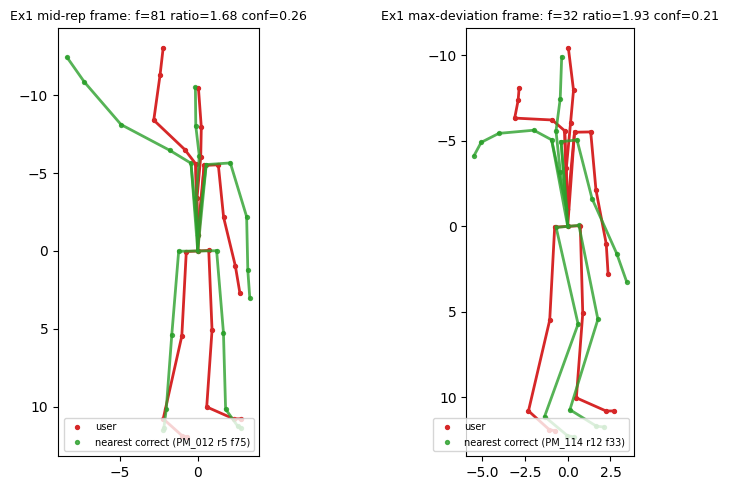


   per-phase-bin thresholds (bin centre -> threshold, n samples):
   0.03:0.83(245)  0.07:0.88(226)  0.12:0.90(229)  0.17:0.93(218)  0.23:0.95(225)  0.28:0.98(227)  0.33:1.03(223)  0.38:1.04(228)  0.42:1.02(234)  0.47:0.93(220)  0.53:0.89(221)  0.57:0.94(225)  0.62:1.00(220)  0.68:1.09(229)  0.72:1.07(226)  0.78:0.96(225)  0.82:0.91(228)  0.88:0.93(227)  0.93:0.89(227)  0.97:1.04(213)
   frame table: 80 reps, 12155 frames, rep length median=141 (min 83, max 316)  <- your live camera fps should give similar lengths
   thresholds (RMS z-distance, 95th pct, LOPO): global=1.169  per-bin min/med/max=1.067/1.161/1.325

   saved /kaggle/working/ghost_models/Ex1_ghost.pkl  (37.2 MB)  [119s]

Ex2
   reps: total=162 train=115 (8 persons) test=47 (3 persons) | test flawed=20
   frame table: 44 reps, 7306 frames, rep length median=160 (min 110, max 301)  <- your live camera fps should give similar lengths
   phase-model CV (median/mean/p90 circular error, fraction of a rep):
     knn          0.0

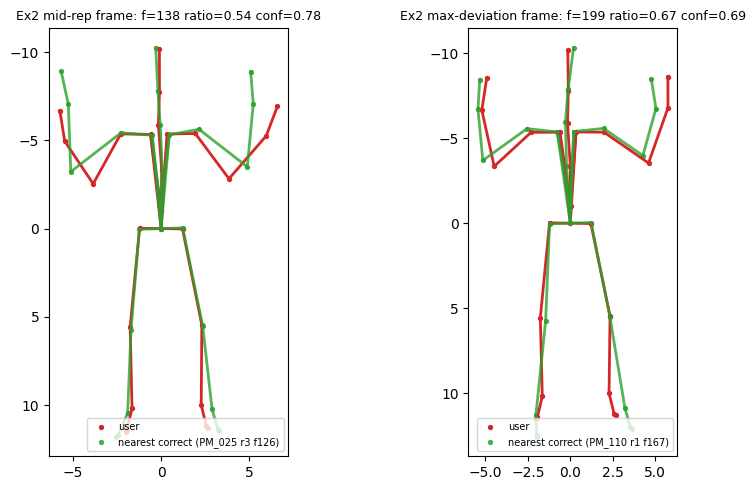


   per-phase-bin thresholds (bin centre -> threshold, n samples):
   0.03:0.86(191)  0.07:0.87(176)  0.12:0.91(183)  0.17:1.10(172)  0.23:1.15(177)  0.28:1.07(185)  0.33:1.05(180)  0.38:1.00(175)  0.42:0.99(185)  0.47:0.95(177)  0.53:0.94(171)  0.57:0.90(185)  0.62:0.92(174)  0.68:0.94(183)  0.72:1.05(176)  0.78:1.18(182)  0.82:1.18(178)  0.88:1.23(181)  0.93:1.04(176)  0.97:1.01(166)
   frame table: 71 reps, 10947 frames, rep length median=141 (min 90, max 301)  <- your live camera fps should give similar lengths
   thresholds (RMS z-distance, 95th pct, LOPO): global=1.065  per-bin min/med/max=0.928/1.046/1.189

   saved /kaggle/working/ghost_models/Ex2_ghost.pkl  (33.3 MB)  [119s]

Ex3
   reps: total=63 train=50 (7 persons) test=13 (2 persons) | test flawed=4
   frame table: 24 reps, 2509 frames, rep length median=100 (min 80, max 130)  <- your live camera fps should give similar lengths
   phase-model CV (median/mean/p90 circular error, fraction of a rep):
     knn          0.040 /

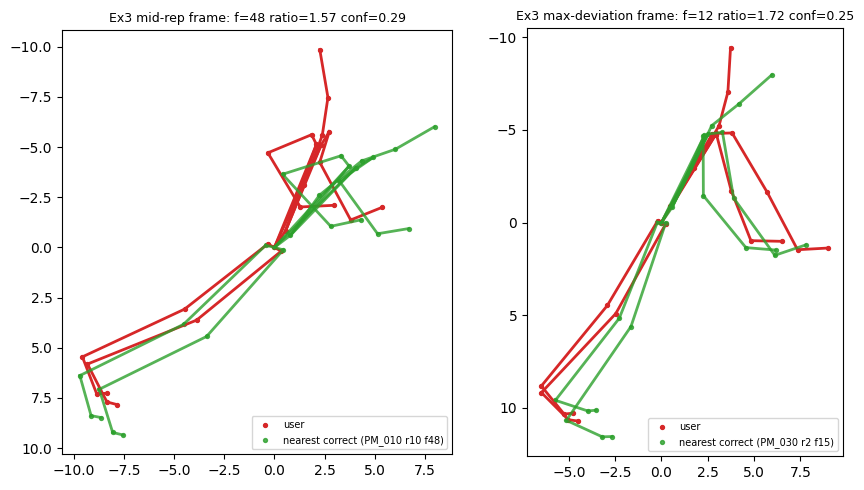


   per-phase-bin thresholds (bin centre -> threshold, n samples):
   0.03:1.00(67)  0.07:1.03(59)  0.12:1.00(62)  0.17:1.02(59)  0.23:1.10(64)  0.28:1.13(61)  0.33:1.12(62)  0.38:1.14(58)  0.42:1.10(68)  0.47:1.14(60)  0.53:1.16(59)  0.57:1.15(61)  0.62:1.15(61)  0.68:1.15(66)  0.72:1.13(59)  0.78:1.16(61)  0.82:1.08(62)  0.88:1.16(67)  0.93:1.27(56)  0.97:1.00(57)
   frame table: 33 reps, 3807 frames, rep length median=105 (min 80, max 210)  <- your live camera fps should give similar lengths
   thresholds (RMS z-distance, 95th pct, LOPO): global=1.057  per-bin min/med/max=0.970/1.039/1.272

   saved /kaggle/working/ghost_models/Ex3_ghost.pkl  (12.0 MB)  [36s]

Ex4
   reps: total=126 train=110 (8 persons) test=16 (3 persons) | test flawed=9
   frame table: 70 reps, 6528 frames, rep length median=95 (min 50, max 135)  <- your live camera fps should give similar lengths
   phase-model CV (median/mean/p90 circular error, fraction of a rep):
     knn          0.084 / 0.116 / 0.260
     e

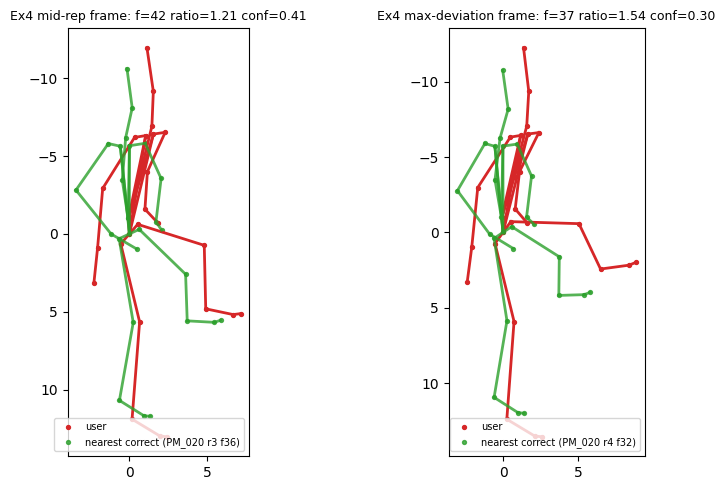


   per-phase-bin thresholds (bin centre -> threshold, n samples):
   0.03:0.89(171)  0.07:0.89(153)  0.12:0.95(152)  0.17:1.04(148)  0.23:1.09(156)  0.28:1.19(160)  0.33:1.23(154)  0.38:1.19(150)  0.42:1.10(173)  0.47:1.10(153)  0.53:1.11(147)  0.57:1.08(159)  0.62:1.18(149)  0.68:1.20(162)  0.72:1.03(152)  0.78:0.99(151)  0.82:1.01(162)  0.88:0.95(158)  0.93:0.90(159)  0.97:0.91(141)
   frame table: 77 reps, 7126 frames, rep length median=91 (min 50, max 135)  <- your live camera fps should give similar lengths
   thresholds (RMS z-distance, 95th pct, LOPO): global=1.081  per-bin min/med/max=0.756/1.017/1.215

   saved /kaggle/working/ghost_models/Ex4_ghost.pkl  (21.9 MB)  [41s]

Ex5
   reps: total=134 train=105 (7 persons) test=29 (2 persons) | test flawed=23
   frame table: 54 reps, 5565 frames, rep length median=101 (min 46, max 170)  <- your live camera fps should give similar lengths
   phase-model CV (median/mean/p90 circular error, fraction of a rep):
     knn          0.079 /

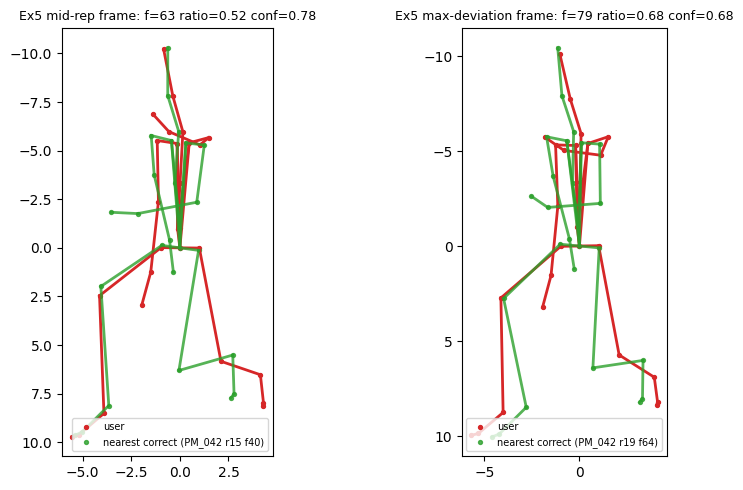


   per-phase-bin thresholds (bin centre -> threshold, n samples):
   0.03:0.94(150)  0.07:0.97(133)  0.12:1.06(141)  0.17:1.15(128)  0.23:1.12(139)  0.28:1.20(131)  0.33:1.11(143)  0.38:1.08(132)  0.42:1.02(145)  0.47:1.01(127)  0.53:1.02(132)  0.57:1.05(133)  0.62:1.09(136)  0.68:1.12(137)  0.72:1.07(136)  0.78:1.10(136)  0.82:1.13(141)  0.88:1.19(135)  0.93:1.26(138)  0.97:1.24(121)
   frame table: 60 reps, 6071 frames, rep length median=100 (min 46, max 170)  <- your live camera fps should give similar lengths
   thresholds (RMS z-distance, 95th pct, LOPO): global=1.110  per-bin min/med/max=0.945/1.113/1.274

   saved /kaggle/working/ghost_models/Ex5_ghost.pkl  (18.7 MB)  [63s]

Ex6
   reps: total=155 train=127 (7 persons) test=28 (2 persons) | test flawed=11
   frame table: 87 reps, 8478 frames, rep length median=91 (min 65, max 148)  <- your live camera fps should give similar lengths
   phase-model CV (median/mean/p90 circular error, fraction of a rep):
     knn          0.043 /

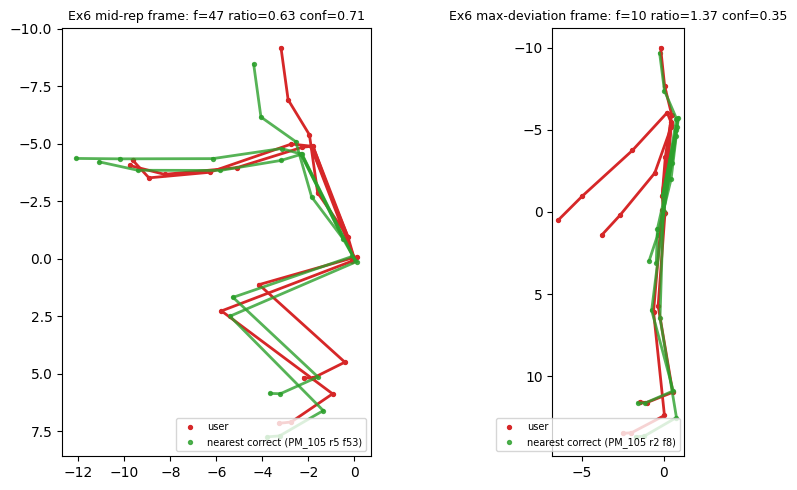


   per-phase-bin thresholds (bin centre -> threshold, n samples):
   0.03:0.72(242)  0.07:0.72(198)  0.12:0.75(208)  0.17:0.76(183)  0.23:0.81(193)  0.28:0.86(213)  0.33:0.85(208)  0.38:0.83(193)  0.42:0.84(220)  0.47:0.85(201)  0.53:0.86(197)  0.57:0.86(198)  0.62:0.92(188)  0.68:0.91(215)  0.72:0.93(200)  0.78:0.90(199)  0.82:0.94(212)  0.88:0.87(203)  0.93:0.85(208)  0.97:0.78(177)
   frame table: 104 reps, 10599 frames, rep length median=96 (min 65, max 160)  <- your live camera fps should give similar lengths
   thresholds (RMS z-distance, 95th pct, LOPO): global=0.866  per-bin min/med/max=0.705/0.855/1.202

   saved /kaggle/working/ghost_models/Ex6_ghost.pkl  (32.7 MB)  [75s]

manifest written -> /kaggle/working/ghost_models/manifest.json


In [9]:
def run_exercise(ex):
    t0 = time.time()
    print("\n" + "=" * 100 + f"\n{ex}\n" + "=" * 100)
    ex_dir = os.path.join(DATA_ROOT, ex)
    if not os.path.isdir(ex_dir):
        print(f"   !! folder not found: {ex_dir} (skipped)")
        return None
    recs = build_records(ex_dir)
    train, test = subject_split(recs, SPLIT_TEST_SIZE, SEED)
    print(f"   reps: total={len(recs)} train={len(train)} ({len({r['person_id'] for r in train})} persons) "
          f"test={len(test)} ({len({r['person_id'] for r in test})} persons) | test flawed={sum(r['label'] == 0 for r in test)}")

    # 1) fit on train persons (correct reps only)
    b_val = fit_bundle(train, ex)

    # 2) validation on held-out persons
    df, summ = validate(b_val, test)
    print("\n   VALIDATION on held-out persons (frame-by-frame replay of every test rep):")
    for k, v in summ.items():
        print(f"     {k:28s} {v:.3f}" if isinstance(v, float) else f"     {k:28s} {v}")
    print("   (AUROC_* = can the cue statistics separate FLAWED from PERFECT reps? 0.5 = no; phase_err = median circular error)")

    # 3) replay one held-out FLAWED rep from frame 0, plus one PERFECT control summary
    flawed = [r for r in test if r["label"] == 0 and load_rep(r["path"]) is not None]
    perfect = [r for r in test if r["label"] == 1 and load_rep(r["path"]) is not None]
    if flawed:
        r0 = flawed[0]
        arr = load_rep(r0["path"])
        rows = replay_rep(b_val, arr, "always")
        print_replay(rows, f"{ex} FLAWED test rep PM_{r0['person_id']} rep{r0['rep']} ({len(arr)} frames)")
        s = rep_summary(rows)
        print(f"\n   this rep: mean ratio={s['mean_ratio']:.2f}  p90 ratio={s['p90_ratio']:.2f}  flagged frames={s['flag_frac'] * 100:.0f}%  "
              f"median phase error={s['phase_err']:.3f}")
        if perfect:
            rp = perfect[0]
            sp = rep_summary(replay_rep(b_val, load_rep(rp["path"]), "none"))
            print(f"   control PERFECT rep PM_{rp['person_id']} rep{rp['rep']}: mean ratio={sp['mean_ratio']:.2f}  "
                  f"p90 ratio={sp['p90_ratio']:.2f}  flagged frames={sp['flag_frac'] * 100:.0f}%")
        rows_to_df(rows).to_csv(os.path.join(OUT_DIR, f"{ex}_replay_flawed_PM_{r0['person_id']}_rep{r0['rep']}.csv"), index=False)
        ghost_figure(rows, ex, os.path.join(OUT_DIR, f"{ex}_ghost_example.png"))
    else:
        print("   no flawed test rep available for the replay demo")

    print("\n   per-phase-bin thresholds (bin centre -> threshold, n samples):")
    print("   " + "  ".join(f"{(i + .5) / N_BINS:.2f}:{t:.2f}({c})" for i, (t, c) in enumerate(zip(b_val['thr_bins'], b_val['thr_counts']))))

    # 4) final refit on ALL persons with the chosen phase model, then save
    b_final = fit_bundle(recs, ex, phase_kind=b_val["phase_kind"])
    pkl = os.path.join(OUT_DIR, f"{ex}_ghost.pkl")
    joblib.dump(b_final, pkl, compress=3)
    print(f"\n   saved {pkl}  ({os.path.getsize(pkl) / 1e6:.1f} MB)  [{time.time() - t0:.0f}s]")
    return dict(exercise=ex, file=os.path.basename(pkl), phase_kind=b_final["phase_kind"], n_correct_reps=b_final["n_correct_reps"],
                n_persons=b_final["n_persons"], thr_global=b_final["thr_global"], thr_bins=b_final["thr_bins"].tolist(),
                validation=summ)


manifest = {}
for ex in EXERCISES:
    try:
        m = run_exercise(ex)
        if m:
            manifest[ex] = m
    except Exception as e:
        import traceback; traceback.print_exc()
        print(f"   !! {ex} failed: {e}")

with open(os.path.join(OUT_DIR, "manifest.json"), "w") as f:
    json.dump(manifest, f, indent=2)
print("\nmanifest written ->", os.path.join(OUT_DIR, "manifest.json"))

## Summary of all exercises

In [10]:
rows = []
for ex, m in manifest.items():
    v = m["validation"]
    rows.append(dict(exercise=ex, phase_model=m["phase_kind"], persons=m["n_persons"], correct_reps=m["n_correct_reps"],
                     thr_global=round(m["thr_global"], 3),
                     phase_err_perfect=round(v.get("PERFECT_phase_err_median", float("nan")), 3),
                     phase_err_flawed=round(v.get("FLAWED_phase_err_median", float("nan")), 3),
                     flagfrac_perfect=round(v.get("PERFECT_flag_frac", float("nan")), 3),
                     flagfrac_flawed=round(v.get("FLAWED_flag_frac", float("nan")), 3),
                     AUROC_mean_ratio=round(v.get("AUROC_mean_ratio", float("nan")), 3),
                     AUROC_flag_frac=round(v.get("AUROC_flag_frac", float("nan")), 3)))
summary = pd.DataFrame(rows)
print(summary.to_string(index=False))

exercise phase_model  persons  correct_reps  thr_global  phase_err_perfect  phase_err_flawed  flagfrac_perfect  flagfrac_flawed  AUROC_mean_ratio  AUROC_flag_frac
     Ex1 extra_trees       12            80       1.169              0.041             0.053             0.637            0.725             0.625            0.635
     Ex2 extra_trees       11            71       1.065              0.047             0.028             0.412            0.547             0.620            0.604
     Ex3 extra_trees        8            33       1.057              0.041             0.086             0.033            0.838             1.000            1.000
     Ex4 extra_trees       10            77       1.081              0.061             0.086             0.084            0.557             0.889            0.913
     Ex5 extra_trees        8            60       1.110              0.029             0.064             0.000            0.031             0.783            0.565
     Ex6 extra_trees  

## How to use the saved models in real time (pose in -> ghost out)
`PoseCoach` takes the exercise name and the 26x2 points of ONE frame. Nothing is batched; call it for every camera frame.

In [11]:
def realtime_example(models_dir=OUT_DIR, exercise="Ex1", frames=None):
    """frames: any iterable of (26,2) arrays (your camera loop). Shown here on a saved rep for demonstration."""
    coach = PoseCoach(models_dir, return_neighbours="flagged")     # "flagged": neighbours only when the threshold is exceeded
    coach.reset(exercise)
    for pts in frames:
        out = coach.push(exercise, pts)
        if out["status"] != "ok":
            continue                                               # warm-up frames: nothing to show
        if out["flag"]:
            ghost = out["neighbours"][0]["pose"]                   # normalised 26x2 pose of the nearest CORRECT frame
            conf = out["neighbours"][0]["confidence"]
            yield out["frame"], out["phase"], out["ratio"], conf, ghost
        # else: user is within the correct range at this phase -> draw no ghost


# demo on one held-out rep (replace `frames` by your camera stream)
demo_ex = next(iter(manifest), None)
if demo_ex:
    recs_demo = build_records(os.path.join(DATA_ROOT, demo_ex))
    r_demo = next((r for r in recs_demo if r["label"] == 0), recs_demo[0])
    arr_demo = load_rep(r_demo["path"])
    n_ghost = sum(1 for _ in realtime_example(OUT_DIR, demo_ex, arr_demo))
    print(f"{demo_ex}: ghost shown on {n_ghost}/{len(arr_demo)} frames of PM_{r_demo['person_id']} rep{r_demo['rep']}")

Ex1: ghost shown on 0/215 frames of PM_001 rep10
